In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import linregress

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columns = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "car_name"]
df = pd.read_csv( url,  sep=r"\s+", names=columns, na_values="?")
print("Dataset loaded successfully!")
print("Original number of rows:", len(df))
display(df.head())



Dataset loaded successfully!
Original number of rows: 398


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [ ]:
df["fuel_consumption"] = 235.214583 / df["mpg"]
df["weight_kg"] = df["weight"] * 0.45359237
print(df[["mpg", "fuel_consumption", "weight", "weight_kg"]].head())

    mpg  fuel_consumption  weight    weight_kg
0  18.0         13.067477  3504.0  1589.387664
1  15.0         15.680972  3693.0  1675.116622
2  18.0         13.067477  3436.0  1558.543383
3  16.0         14.700911  3433.0  1557.182606
4  17.0         13.836152  3449.0  1564.440084


In [ ]:
original_rows = len(df)
df_clean = df.dropna(subset=["fuel_consumption", "weight_kg"]).copy()
df_clean = df_clean[(df_clean["fuel_consumption"] > 0) & (df_clean["weight_kg"] > 0)].copy()
cleaned_rows = len(df_clean)
removed_rows = original_rows - cleaned_rows
print("Original rows:", original_rows)
print("Cleaned rows:", cleaned_rows)
print("Rows removed:", removed_rows)


Original rows: 398
Cleaned rows: 398
Rows removed: 0


In [ ]:
x = df_clean["weight_kg"].to_numpy()
y = df_clean["fuel_consumption"].to_numpy()
result = linregress(x, y)
slope = result.slope
intercept = result.intercept
r_squared = result.rvalue**2
p_value = result.pvalue
std_error = result.stderr
print("Regression results")
print("------------------")
print("Slope:", slope)
print("Intercept:", intercept)
print("R-squared:", r_squared)
print("P-value:", p_value)
print("Standard error:", std_error)

Regression results
------------------
Slope: 0.00899246703153055
Intercept: -0.9030520509041953
R-squared: 0.7836118983544513
P-value: 1.0756614433423283e-133
Standard error: 0.00023746381400531922


In [ ]:
n = len(x)
degrees_of_freedom = n - 2
t_critical = stats.t.ppf( 0.975, degrees_of_freedom)
margin_error = t_critical * std_error
lower_ci = slope - margin_error
upper_ci = slope + margin_error
print("Slope:", slope)
print("95% Confidence Interval:")
print("Lower limit:", lower_ci)
print("Upper limit:", upper_ci)

Slope: 0.00899246703153055
95% Confidence Interval:
Lower limit: 0.008525619677693401
Upper limit: 0.009459314385367698


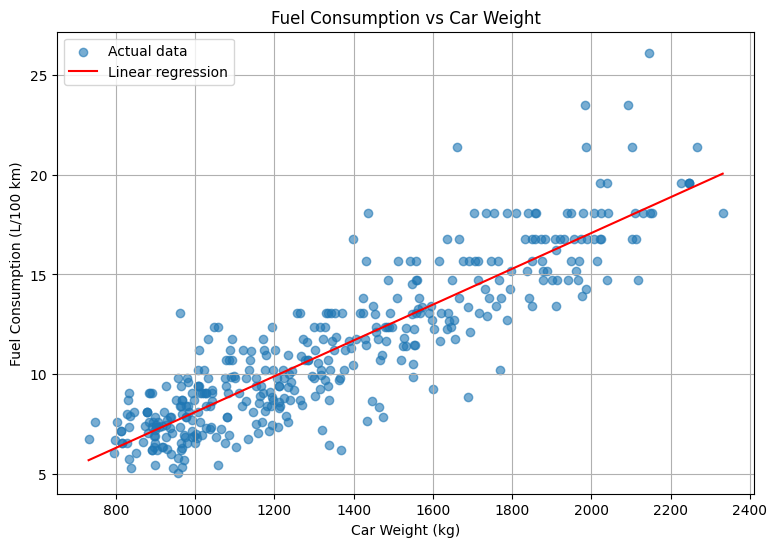

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter( x, y, alpha=0.6, label="Actual data")
x_sorted = np.sort(x)
plt.plot(x_sorted, slope * x_sorted + intercept,   color="red", label="Linear regression")
plt.xlabel("Car Weight (kg)")
plt.ylabel("Fuel Consumption (L/100 km)")
plt.title("Fuel Consumption vs Car Weight")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
Crr = 0.012
g = 9.81
distance = 100000
efficiency = 0.2
energy_per_litre = 32e6
theoretical_slope = (Crr * g * distance /(efficiency * energy_per_litre))
print("Theoretical slope:",  theoretical_slope, "L/100 km per kg")
print("Experimental slope:",  slope, "L/100 km per kg")


Theoretical slope: 0.001839375 L/100 km per kg
Experimental slope: 0.00899246703153055 L/100 km per kg


In [ ]:
ratio = slope / theoretical_slope
print("Experimental slope:", slope)
print("Theoretical slope:", theoretical_slope)
print("Ratio:", ratio)


Experimental slope: 0.00899246703153055
Theoretical slope: 0.001839375
Ratio: 4.888870965154223


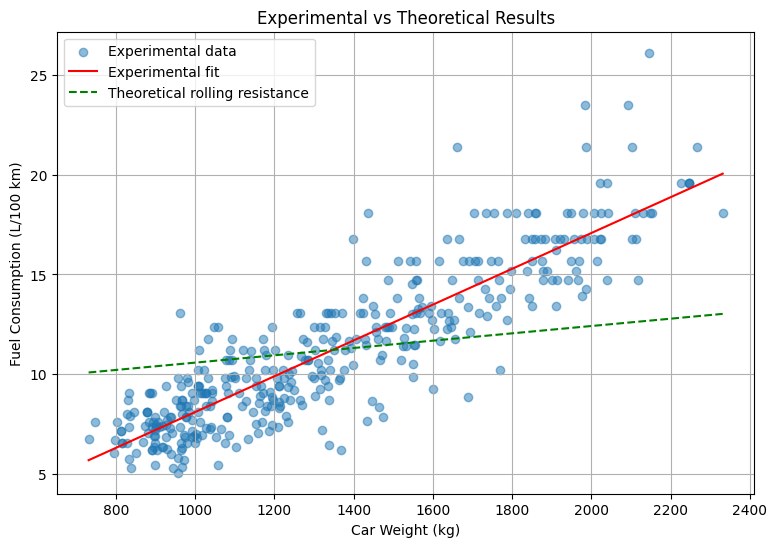

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter( x, y, alpha=0.5, label="Experimental data")
x_sorted = np.sort(x)
plt.plot(x_sorted, slope * x_sorted + intercept, color="red", label="Experimental fit")
theoretical_line = (theoretical_slope * x_sorted + (np.mean(y) - theoretical_slope * np.mean(x)))
plt.plot( x_sorted, theoretical_line, linestyle="--", color="green", label="Theoretical rolling resistance")
plt.xlabel("Car Weight (kg)")
plt.ylabel("Fuel Consumption (L/100 km)")
plt.title("Experimental vs Theoretical Results")
plt.legend()
plt.grid(True)
plt.show()
